Постановка задачи 

Онлайн-кинотеатр хочет автоматически анализировать отзывы зрителей на фильмы, чтобы без ручного прочтения определять общее отношение аудитории - понравился фильм или нет, и использовать это для оценки картины. Для этого используется набор данных, который включает 50 000 строк и 2 столбца (1 признак - текст отзыва, и 1 таргет — тональность).

Целевая переменная бинарная: positive или negative. Задача сводится к бинарной классификации текста: по тексту отзыва предсказать его тональность.

In [4]:
%load_ext autoreload
%autoreload 2

In [42]:
import pandas as pd
import numpy as np 
import random 
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from nlp import *
from collections import Counter
from nltk.corpus import stopwords
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import f_classif

In [6]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

1. Изучение структуры данных 

In [7]:
df = pd.read_csv('IMDB Dataset.csv')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


Количество записей - 50000 , количество столбцов - 2, пропуски отсутствуют 

2. Проверка на корректность и качество данных 

2.1 Проверка на дубликаты

In [9]:
print(df.duplicated().sum())

418


Дубликаты присутствуют, хотя их всего 418 штук, что примерно 0,8 % от всех записей всего датасета. Однако хотя это ничтожная доля, при разделении датасета эти дубликаты могу проникнуть в разные выборки, что приведет к утечке данных и метрики завысятся. Также это может привести к переобучению, если модель будет смотреть на один и тот же текст, хотя при такой доле этот эффект не будет сильно заметен. В любом случае дубликаты нужно будет убрать, но потом

2.2 Пропущенные значения

In [10]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

Пропуски отсутствуют 

Теперь я хочу проверить есть ли у нас мусорные отзывы. Они могут быть не пустыми, но не содержать в себе информации, как правило такие отзывы короткие. 

In [11]:
df["review_len"] = df["review"].str.strip().str.len() #убираем пробелы и переносы и возвращаем длину каждой строки

threshold = 50 # порог короткого отзыва, может меняться
short_mask = df["review_len"] < threshold # маска на короткие отзывы

n_short = short_mask.sum() # сумма коротких и потенциально мусорных отзывов
print(n_short)

df.loc[short_mask, ['review', 'sentiment', 'review_len']].sort_values('review_len')

3


,review,sentiment,review_len
27521,"Read the book, forget the movie!",negative,32
31072,"What a script, what a story, what a mess!",negative,41
40817,I hope this group of film-makers never re-unites.,negative,49


Как можем видеть самые короткие отзывы не являются мусорными, так что ни явных ни скрытых пропусков в датасете нет 

3. Детальное изучение признака и таргета 

In [12]:
# Сделаем копию исходного датасета для EDA, чтобы не менять исходные данные и спокойно экспериментировать 

df_EDA = df.copy()

3.1 Таргет

In [13]:
df_EDA["sentiment"].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Идеальный баланс в таргете. Значит такие метрики как accuracy и ROС-AUC уже не так страшны. 

3.2 Анализ отзывов

In [14]:
# Для начала надо посмотреть хотя бы на 3 полных отзыва 

for text in df_EDA["review"].head(3):
    print(text)
    print(' ')

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fac

Тут мы видим метки <br /> в тексте, значит отзывы собраны с веб-страниц, что логично. Такой мусор нужно будет почистить

Сделаем удаление в копии, чтобы продолжить анализ текста на чистом тексте. Функция strip_html была выведена в nlp.py 

In [15]:
df_EDA["review_clean"] = df_EDA["review"].apply(strip_html)

Теперь посмотрим распределение длины отзывов

In [16]:
df_EDA["review_length"] = df_EDA["review"].str.len()

In [ ]:
df_EDA["review_length"].describe()

count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: review_length, dtype: float64

<Axes: xlabel='review_length', ylabel='Count'>

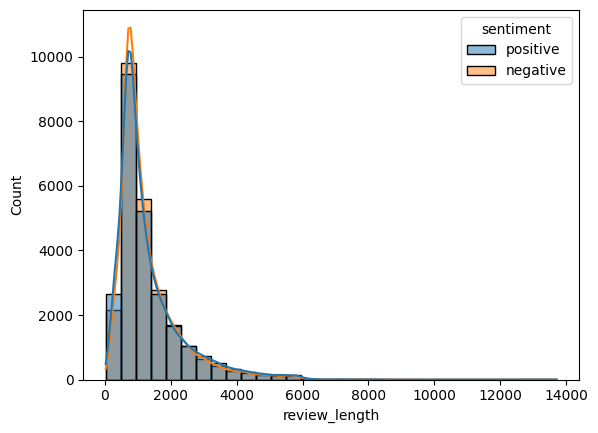

In [18]:
sns.histplot(data=df_EDA, x="review_length", bins=30, kde=True, hue="sentiment")

Здесь видно длинный правый хвост, очевидно ведь средняя длина больше медианной. Однако для сравнения двух классов график нечитаем, попробуем ограничить длину графика, примерно на 3000, где в основном находятся данные

(0.0, 3000.0)

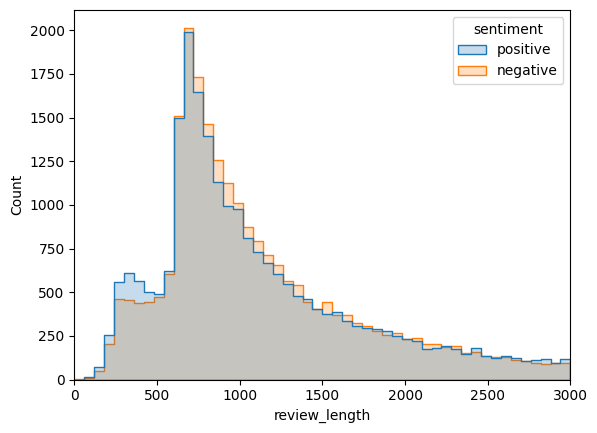

In [19]:
sns.histplot(data=df_EDA, x="review_length", bins=50, hue="sentiment", binrange=(0, 3000), element="step")
plt.xlim(0, 3000) #обрезаем хвост

Кривые двух классов совпадают, перейдем к токенизации и частотному анализу слов

In [20]:
# Токенизация отзывов по словам 
df_EDA["tokens"] = df_EDA["review_clean"].apply(tokenize)

In [21]:
# Посчитаем частоту каждого токена в отзывах
stop_words = set(stopwords.words("english")) # Стоп слова 
all_counter = count_tokens(df_EDA["tokens"], stop_words)
all_counter.most_common(20)


[('movie', 87935),
 ('film', 79672),
 ('one', 53585),
 ('like', 40160),
 ('good', 29737),
 ('time', 25100),
 ('even', 24855),
 ('would', 24599),
 ('story', 23108),
 ('really', 23089),
 ('see', 23021),
 ('well', 21259),
 ('much', 19314),
 ('bad', 18461),
 ('get', 18413),
 ('people', 18182),
 ('great', 18136),
 ('also', 17972),
 ('first', 17576),
 ('made', 16150)]

Тут я хочу заметить, что для тональности важны такие слова как not, no, dont и тд, так как они влияют на тональность отзыва. Возможно нужно будет сделать для них исключение, попробуем в baseline

<Axes: xlabel='count', ylabel='word'>

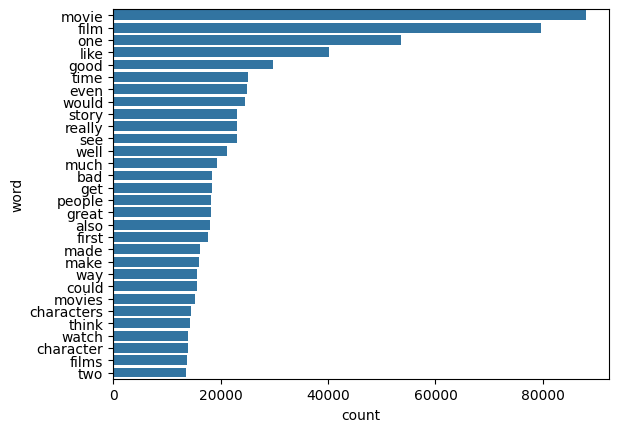

In [ ]:
# Визуализируем частоту слов через график
top_words = pd.DataFrame(all_counter.most_common(30), columns=["word", "count"])
sns.barplot(data=top_words, x="count", y="word")

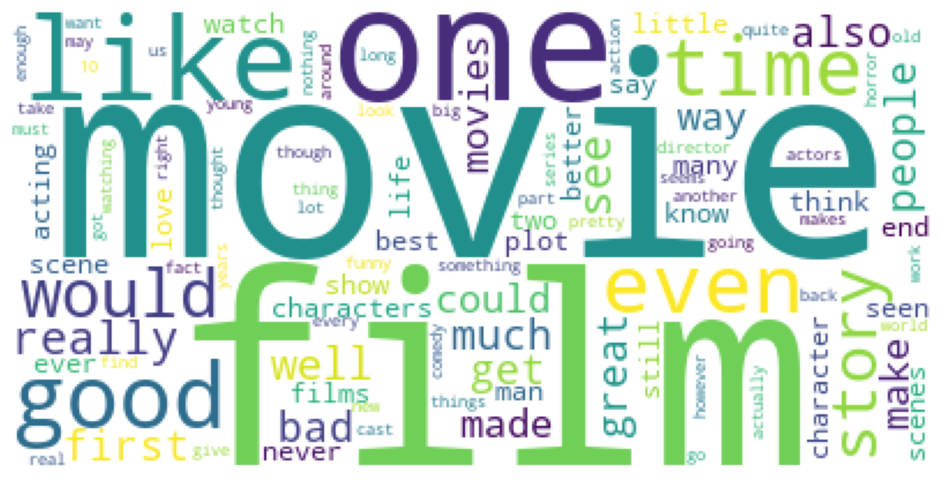

In [33]:
wc = WordCloud(background_color="white", max_words=100).generate_from_frequencies(all_counter)

plt.figure(figsize=(12, 6))
plt.imshow(wc)
plt.axis("off")
plt.show()

Теперь посмотрим какие токены чаще всего встречаются в каждом классе

In [40]:
positive = df_EDA[df_EDA["sentiment"] == "positive"]
negative = df_EDA[df_EDA["sentiment"] == "negative"]

top_pos = count_tokens(positive["tokens"], stop_words).most_common(20)
top_neg = count_tokens(negative["tokens"], stop_words).most_common(20)

print(top_pos)
print(top_neg)

[('film', 42093), ('movie', 37845), ('one', 27312), ('like', 17709), ('good', 15020), ('great', 12961), ('story', 12931), ('time', 12746), ('well', 12724), ('see', 12271), ('also', 10792), ('really', 10735), ('would', 10594), ('even', 9612), ('first', 9228), ('much', 9200), ('people', 8716), ('love', 8688), ('best', 8509), ('get', 8285)]
[('movie', 50090), ('film', 37579), ('one', 26273), ('like', 22451), ('even', 15243), ('good', 14717), ('bad', 14714), ('would', 14005), ('time', 12354), ('really', 12354), ('see', 10750), ('story', 10177), ('get', 10128), ('much', 10114), ('people', 9466), ('make', 9348), ('could', 9299), ('made', 8800), ('well', 8535), ('first', 8348)]


Большинство слов есть в обоих топах, они не являются маркерами тональности. Что интересно: слово good есть в обоих топах и стоит одинаково высоко, значит видимо отрицания действительно несут смысл и выкидывать not опасно

Сейчас буду делать анализ важности токенов с помощью ANOVA F-test

In [44]:
# Переводим таргет в числа 
y = (df_EDA["sentiment"] == "positive").astype(int)

# Векторизуем текст в матрицу 
vectorizer = CountVectorizer(stop_words="english", min_df=50)
X = vectorizer.fit_transform(df_EDA["review_clean"])

# Считаем F-score для каждого слова
f_scores, p_values = f_classif(X, y)

importance = pd.DataFrame({
    "token": vectorizer.get_feature_names_out(),
    "f_score": f_scores
}).sort_values("f_score", ascending=False)

importance.head(20)

,token,f_score
790,bad,3590.015259
9815,worst,2922.527867
3962,great,2180.766746
9621,waste,1901.587061
763,awful,1695.343802
3179,excellent,1377.889289
8891,terrible,1295.226057
9813,worse,1140.049312
1101,boring,1121.377247
9783,wonderful,1115.803681


Вот тут уже видно, что высокие скоры получили слова, которые явно относятся к тональности позитивного или негативного отзыва

Попробую убрать stop_words и проделать то же самое с биграммами, возможно not good тоже появится как сильный маркер

In [45]:
vectorizer = CountVectorizer(min_df=50, ngram_range=(1, 2))
X = vectorizer.fit_transform(df_EDA["review_clean"])

# Считаем F-score для каждого слова
f_scores, p_values = f_classif(X, y)

importance = pd.DataFrame({
    "token": vectorizer.get_feature_names_out(),
    "f_score": f_scores
}).sort_values("f_score", ascending=False)

importance.head(20)

,token,f_score
3267,bad,3590.015259
32574,worst,2922.527867
27883,the worst,2505.929021
11182,great,2180.766746
31147,waste,1901.587061
3199,awful,1695.343802
8827,excellent,1377.889289
25932,terrible,1295.226057
32563,worse,1140.049312
4263,boring,1121.377247


Биграммы в топе F-теста это по сути двойники своих униграмм (the worst и worst) , нового сигнала почти нет. Я думал, что появится неодназначное слово по типу not good, но ее здесь нет. При этом биграммы увеличивают словарь, что влияет на занимаемую память, скорость обучения и переобучение, так что тут гипотеза с неочевидной выгодой. 